## part 1

In [23]:
pip install numpy scikit-learn matplotlib torch torchvision torchaudio pandas seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [24]:
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import torch
import pandas as pd
import seaborn as sns

In [25]:
import pandas as pd
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [26]:
pip install rdkit


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [27]:
# loading the csv file

train1_path = "part1_train.csv"
valid1_path = "part1_val.csv"
test1_path = "part1_test.csv"

df_train1 = pd.read_csv(train1_path)
df_valid1 = pd.read_csv(valid1_path)
df_test1 = pd.read_csv(test1_path)

In [28]:
from sklearn.metrics import f1_score

LABELS = ["Safety", "Funding", "Efficacy", "Recruitment", "Other"]


def evaluate(y_true, y_pred, name=None, verbose=True):
    """Score multi-label predictions with the metrics the assignment asks for.

    y_true, y_pred: arrays or DataFrames of shape (n_trials, 5) holding 0/1,
    with columns in LABELS order. Pass predicted labels, not probabilities.

    Returns a dict with sample_f1, macro_f1, and one F1 per label, so results
    can be collected into a comparison table:
        pd.DataFrame([evaluate(...), evaluate(...)])
    """
    y_true = y_true[LABELS].values if isinstance(y_true, pd.DataFrame) else np.asarray(y_true)
    y_pred = y_pred[LABELS].values if isinstance(y_pred, pd.DataFrame) else np.asarray(y_pred)

    if y_true.shape != y_pred.shape or y_true.ndim != 2 or y_true.shape[1] != len(LABELS):
        raise ValueError(f"Expected matching (n, {len(LABELS)}) shapes, got {y_true.shape} and {y_pred.shape}")
    # Catches masked train rows (-100) and probabilities passed by mistake
    for arr, arg in [(y_true, "y_true"), (y_pred, "y_pred")]:
        if not np.isin(arr, [0, 1]).all():
            raise ValueError(f"{arg} must contain only 0 and 1")

    y_true, y_pred = y_true.astype(int), y_pred.astype(int)

    # zero_division=0: a trial or label with nothing predicted scores 0, not an error
    results = {
        "sample_f1": float(f1_score(y_true, y_pred, average="samples", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    }
    per_label = f1_score(y_true, y_pred, average=None, zero_division=0)
    results.update(zip(LABELS, per_label.tolist()))

    if verbose:
        title = f"{name}: " if name else ""
        scores = "  ".join(f"{label} {results[label]:.3f}" for label in LABELS)
        print(f"{title}sample F1 {results['sample_f1']:.3f} | macro F1 {results['macro_f1']:.3f}\n  {scores}")

    return {"model": name, **results} if name else results

standardize the individual dimensions before using it

multi hot encode the drug knowledge feature

remove id from models

<!-- What are we trying to achieve? -->

Part 1: Use at least one unsupervised learning method (optionally combined with supervised
learning techniques) to automate the addition of labels to the data examples with missing
labels (i.e., augment your dataset). Generate missing reason labels in part1_train.csv, se-
lect a model and combinations of features using validation performance on part1_val.csv,
and predict the five reason labels for part1_test.csv. Discuss the features you choose and
why some features fail to improve the model performance.

<!-- AI description, need to reword/remove -->

Why Standardize First? PCA identifies directions of maximum variance. If one feature is measured in kilometers and another in millimeters, the larger-scale feature will dominate the covariance matrix and falsely skew the principal components

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

emb_features = [f"emb_{i}" for i in range(150)]

X = df_train1[emb_features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

n_dims = 20
# Fit, then transform, so train, validation and test rows are all projected the same way
pca = PCA(n_components=n_dims, random_state=0).fit(X_scaled)
X_pca = pca.transform(X_scaled)

# Check explained variance ratio
print("Explained variance ratio per component:", pca.explained_variance_ratio_)
print("Total cumulative variance retained:", np.sum(pca.explained_variance_ratio_))

In [30]:
df_train1.head()

,ID,start_year,criteria,diseases_cleaned,drugs,icdcodes,matched_drugs,drug_targets,drug_actions,drug_pathways,drug_smiles,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,emb_7,emb_8,emb_9,emb_10,emb_11,emb_12,emb_13,emb_14,emb_15,emb_16,emb_17,emb_18,emb_19,emb_20,emb_21,emb_22,emb_23,emb_24,emb_25,emb_26,emb_27,emb_28,emb_29,emb_30,emb_31,emb_32,emb_33,emb_34,emb_35,emb_36,emb_37,emb_38,emb_39,emb_40,emb_41,emb_42,emb_43,emb_44,emb_45,emb_46,emb_47,emb_48,emb_49,emb_50,emb_51,emb_52,emb_53,emb_54,emb_55,emb_56,emb_57,emb_58,emb_59,emb_60,emb_61,emb_62,emb_63,emb_64,emb_65,emb_66,emb_67,emb_68,emb_69,emb_70,emb_71,emb_72,emb_73,emb_74,emb_75,emb_76,emb_77,emb_78,emb_79,emb_80,emb_81,emb_82,emb_83,emb_84,emb_85,emb_86,emb_87,emb_88,emb_89,emb_90,emb_91,emb_92,emb_93,emb_94,emb_95,emb_96,emb_97,emb_98,emb_99,emb_100,emb_101,emb_102,emb_103,emb_104,emb_105,emb_106,emb_107,emb_108,emb_109,emb_110,emb_111,emb_112,emb_113,emb_114,emb_115,emb_116,emb_117,emb_118,emb_119,emb_120,emb_121,emb_122,emb_123,emb_124,emb_125,emb_126,emb_127,emb_128,emb_129,emb_130,emb_131,emb_132,emb_133,emb_134,emb_135,emb_136,emb_137,emb_138,emb_139,emb_140,emb_141,emb_142,emb_143,emb_144,emb_145,emb_146,emb_147,emb_148,emb_149,Safety,Funding,Efficacy,Recruitment,Other
0,TR08860,2003,\n Inclusion Criteria:\n\n - ...,"['lung cancer, non-small cell']",['gw572016 (lapatinib)'],"[""['C78.00', 'C78.01', 'C78.02', 'D14.30', 'D1...",NaN,NaN,NaN,NaN,NaN,0.027992,-0.048721,0.041561,-0.036744,-0.034551,-0.008733,0.127167,-0.059490,0.005950,0.025659,-0.052028,0.069712,0.067765,-0.007832,0.017061,0.030029,-0.078079,0.089585,-0.032169,0.043495,0.022025,-0.007740,0.043950,-0.001672,-0.043591,-0.013338,-0.056687,-0.010728,0.067488,0.008230,0.053705,-0.033272,0.166371,-0.020497,-0.116510,0.029872,0.050678,0.016406,-0.041973,-0.028451,0.024443,-0.009696,-0.020425,0.088661,0.034053,0.043858,-0.064830,-0.040979,0.027716,-0.000351,-0.007077,0.062167,-0.018925,0.015197,0.002403,0.056177,-0.001322,0.073114,0.006366,-0.002286,-0.025736,0.067697,0.079625,0.031018,0.004858,0.016977,-0.014439,-0.016208,0.048846,0.016468,0.082563,-0.047588,0.005653,0.023173,-0.010796,-0.052324,-0.000019,-0.026651,0.008823,-0.001215,-0.025645,-0.038260,-0.072652,-0.087668,-0.031835,-0.070319,0.025116,-0.025880,-0.062454,0.041323,0.002947,-0.009193,-0.042828,-0.047257,-0.020045,-0.015978,-0.059855,0.072461,0.074561,0.058299,-0.009993,-0.007569,-0.103589,-0.010309,0.097891,-0.003481,0.108865,-0.004588,-0.017028,0.031807,0.072839,-0.053576,0.112170,0.026439,0.015783,-0.031898,0.090830,-0.032847,0.053346,-0.040523,0.026620,0.060459,-0.075358,0.003882,-0.004470,-0.041597,-0.007057,-0.048812,0.129653,-0.011139,-0.043767,-0.034478,0.031418,-0.053003,-0.040482,-0.028494,-0.059050,0.006313,-0.061804,-0.056993,0.092593,-0.002422,0.014122,-0.048333,-0.067501,0.057633,-0.018126,-0.130373,-0.072231,-0.051629,-100,-100,-100,-100,-100
1,TR03494,2004,\n DISEASE CHARACTERISTICS:\n\n ...,['leukemia'],"['autologous tumor cell vaccine', 'therapeutic...","[""['C95.91', 'C95.92', 'Z80.6', 'Z85.6', 'C90....",NaN,NaN,NaN,NaN,NaN,0.018032,0.040984,0.005138,-0.007580,-0.001913,0.053096,-0.046605,0.066017,-0.050683,-0.041512,0.049991,-0.009812,0.006520,-0.124587,-0.004899,0.008787,-0.082354,0.047716,-0.045330,-0.027143,-0.093978,0.018170,-0.010242,-0.018159,0.034437,-0.032980,-0.072060,0.039595,0.034805,0.018639,0.042504,-0.098434,-0.050905,-0.015272,0.001567,0.017202,0.048105,0.063076,-0.039502,0.033010,-0.058318,-0.007228,-0.047405,-0.018002,0.012781,0.029888,-0.013701,0.011685,0.024712,0.027450,0.031802,0.041615,0.076032,0.064382,-0.050498,-0.014396,-0.031101,-0.016758,0.122778,0.015737,-0.040609,0.027167,-0.020783,0.023383,0.011854,-0.039925,-0.000725,-0.005701,-0.047146,-0.013897,0.009971,-0.078641,-0.021084,-0.040919,-0.017795,0.008660,0.055174,0.004140,0.001910,-0.040934,0.003719,0.003067,0.067235,0.018015,0.104488,0.084722,-0.015796,-0.081126,0.004465,0.065363,0.006019,-0.000359,0.019467,0.000927,0.007745,0.034657,-0.107525,

In [31]:
df_train1.describe()

,start_year,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,emb_7,emb_8,emb_9,emb_10,emb_11,emb_12,emb_13,emb_14,emb_15,emb_16,emb_17,emb_18,emb_19,emb_20,emb_21,emb_22,emb_23,emb_24,emb_25,emb_26,emb_27,emb_28,emb_29,emb_30,emb_31,emb_32,emb_33,emb_34,emb_35,emb_36,emb_37,emb_38,emb_39,emb_40,emb_41,emb_42,emb_43,emb_44,emb_45,emb_46,emb_47,emb_48,emb_49,emb_50,emb_51,emb_52,emb_53,emb_54,emb_55,emb_56,emb_57,emb_58,emb_59,emb_60,emb_61,emb_62,emb_63,emb_64,emb_65,emb_66,emb_67,emb_68,emb_69,emb_70,emb_71,emb_72,emb_73,emb_74,emb_75,emb_76,emb_77,emb_78,emb_79,emb_80,emb_81,emb_82,emb_83,emb_84,emb_85,emb_86,emb_87,emb_88,emb_89,emb_90,emb_91,emb_92,emb_93,emb_94,emb_95,emb_96,emb_97,emb_98,emb_99,emb_100,emb_101,emb_102,emb_103,emb_104,emb_105,emb_106,emb_107,emb_108,emb_109,emb_110,emb_111,emb_112,emb_113,emb_114,emb_115,emb_116,emb_117,emb_118,emb_119,emb_120,emb_121,emb_122,emb_123,emb_124,emb_125,emb_126,emb_127,emb_128,emb_129,emb_130,emb_131,emb_132,emb_133,emb_134,emb_135,emb_136,emb_137,emb_138,emb_139,emb_140,emb_141,emb_142,emb_143,emb_144,emb_145,emb_146,emb_147,emb_148,emb_149,Safety,Funding,Efficacy,Recruitment,Other
count,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000
mean,2005.793339,0.000117,0.000254,0.001937,-0.001087,-0.001516,0.000772,-0.002771,0.000408,0.002274,-0.003171,0.000601,-0.001445,-0.003431,-0.001748,0.000122,0.003502,0.002579,0.000443,0.001017,0.000186,-0.002729,0.001640,-0.001761,-0.002206,0.002435,-0.002509,-0.000509,0.001049,0.000006,-0.002303,-0.000891,0.002320,-0.002992,0.001507,0.003722,0.001017,0.000971,-0.002038,-0.000465,-0.002409,-0.002196,0.003640,0.000120,0.001822,0.000464,0.000233,-0.002866,0.000986,-0.000323,-0.002221,0.000881,0.000616,0.001831,0.000818,-0.000690,0.002361,-0.001390,-0.000945,0.000859,0.002990,0.000519,0.000582,-0.000346,-0.002760,-0.000890,-0.003841,0.000741,-0.000392,0.002043,-0.001502,0.001282,0.000516,-0.000003,-0.000597,0.003781,0.000460,-0.000071,0.004376,-0.003101,0.000757,-0.000219,0.000160,0.000925,0.000730,0.001046,0.001525,-0.002972,0.000149,0.002727,0.000122,0.002267,-0.001630,-0.000127,-0.000494,0.001510,0.001376,-0.002963,-0.001172,-0.001969,-0.000170,-0.001207,-0.0048

In [32]:
# Measure baseline
from sklearn.linear_model import LogisticRegression

labeled = df_train1["Safety"] != -100

# Fit the scaler on train only, then apply it to validation
scaler = StandardScaler().fit(df_train1[emb_features])
X_train = scaler.transform(df_labeled_embs := df_train1.loc[labeled, emb_features])
X_val = scaler.transform(df_valid1[emb_features])

# Train one yes/no classifier per label
val_preds = np.column_stack([
    LogisticRegression(C=1, max_iter=2000, class_weight="balanced")
    .fit(X_train, df_train1.loc[labeled, label])
    .predict(X_val)
    for label in LABELS
])

evaluate(df_valid1[LABELS], val_preds, name="LR baseline")


LR baseline: sample F1 0.848 | macro F1 0.745
  Safety 0.824  Funding 0.667  Efficacy 0.720  Recruitment 0.990  Other 0.526


{'model': 'LR baseline',
 'sample_f1': 0.8482905982905984,
 'macro_f1': 0.7452821715608093,
 'Safety': 0.8235294117647058,
 'Funding': 0.6666666666666666,
 'Efficacy': 0.72,
 'Recruitment': 0.98989898989899,
 'Other': 0.5263157894736842}

<!-- AI description -->

GMM provides soft assignments (probabilities) and can handle elliptical cluster shapes by learning the data's covariance structure

[[0.01059608 0.10695818 0.05964918 0.76873618 0.22941252]
 [0.00940016 0.10713026 0.05948878 0.77080749 0.2290783 ]
 [0.00940014 0.10713026 0.05948878 0.77080753 0.22907829]
 ...
 [0.31457655 0.04242068 0.33596044 0.14875241 0.17300582]
 [0.00940014 0.10713026 0.05948877 0.77080753 0.22907828]
 [0.00958017 0.1068285  0.0594907  0.77092822 0.22853959]]


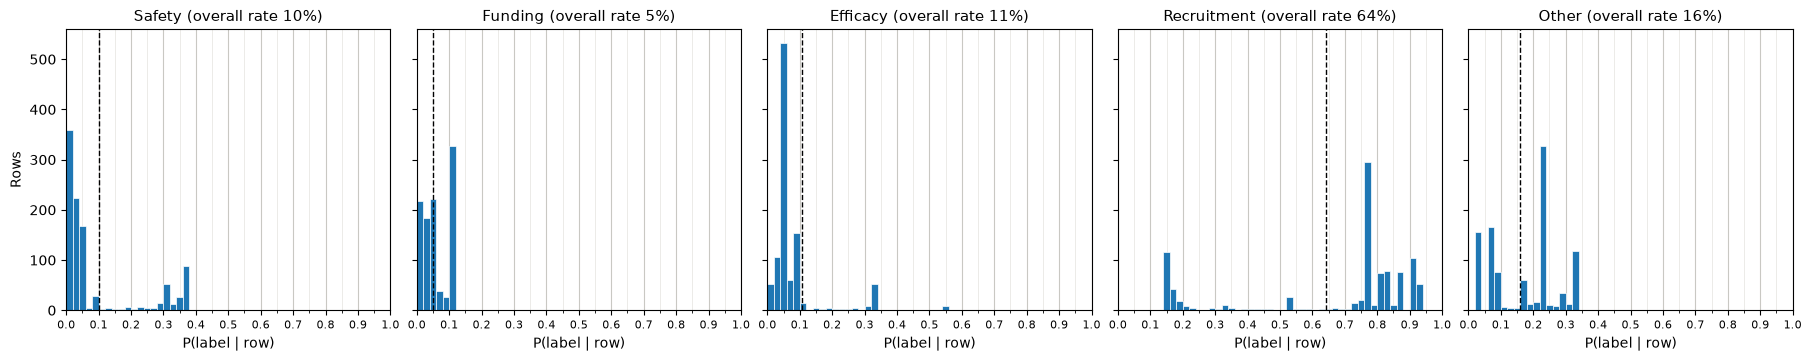

In [36]:
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs


gmm = GaussianMixture(n_components=10, covariance_type="diag", random_state=0)
gmm.fit(X_pca)

probs = gmm.predict_proba(X_pca)

labeled = (df_train1["Safety"] != -100).values
Y = df_train1.loc[labeled, LABELS].values          # (157, 5)
R = probs[labeled]                                 # (157, 10)

# Smoothed toward the overall label rate, since small clusters give noisy rates
strength = 5
base_rate = Y.mean(axis=0)
cluster_rates = (R.T @ Y + strength * base_rate) / (R.sum(axis=0, keepdims=True).T + strength)

label_probs = probs @ cluster_rates                # (1171, 5)

# use label_probs to assign lables to unlabled rows

print(label_probs)


def plot_label_probs(label_probs, base_rate):
    """Plot one histogram of predicted probabilities per label."""
    fig, axes = plt.subplots(1, len(LABELS), figsize=(18, 3.5), sharex=True, sharey=True, layout="constrained")

    for j, (ax, label) in enumerate(zip(axes, LABELS)):
        ax.hist(label_probs[:, j], bins=np.linspace(0, 1, 51), edgecolor="white", linewidth=0.5)
        ax.axvline(base_rate[j], color="black", linestyle="--", linewidth=1)
        ax.set_title(f"{label} (overall rate {base_rate[j]:.0%})", fontsize=11)
        ax.set_xlabel("P(label | row)")

        # Labeled gridlines every 0.1, unlabeled every 0.05
        ax.set_xlim(0, 1)
        ax.set_xticks(np.arange(0, 1.01, 0.1))
        ax.set_xticks(np.arange(0, 1.01, 0.05), minor=True)
        ax.tick_params(axis="x", labelsize=8)
        ax.grid(axis="x", which="major", color="#c9c8c3", linewidth=0.8)
        ax.grid(axis="x", which="minor", color="#e4e3df", linewidth=0.5)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Rows")
    plt.show()


plot_label_probs(label_probs[~labeled], base_rate)




In [43]:
from sklearn.metrics import precision_score, recall_score

# Label probabilities for validation rows, to check cutoffs against true labels
val_probs = gmm.predict_proba(pca.transform(X_val)) @ cluster_rates


def score_cutoffs(j, low, high):
    label = LABELS[j]
    y = df_train1[label].values.copy()
    p = label_probs[:, j]

    y[~labeled & (p >= high)] = 1
    y[~labeled & (p <= low)] = 0
    keep = y != -100                # uncertain rows stay out of this label's training

    clf = LogisticRegression(C=1, max_iter=2000, class_weight="balanced")
    clf.fit(X_scaled[keep], y[keep])

    y_val = df_valid1[label].values
    preds = clf.predict(X_val)
    return {
        "added_pos": int((~labeled & (p >= high)).sum()),
        "added_neg": int((~labeled & (p <= low)).sum()),
        "f1": f1_score(y_val, preds, zero_division=0),
        "precision": precision_score(y_val, preds, zero_division=0),
        "recall": recall_score(y_val, preds, zero_division=0),
    }


def check_cutoffs(j, low, high):
    """How accurate would these cutoffs' labels be on validation rows?"""
    y_val = df_valid1[LABELS[j]].values
    p = val_probs[:, j]
    above, below = p >= high, p <= low
    return {
        "val_above_high": int(above.sum()),
        "high_precision": y_val[above].mean() if above.any() else np.nan,  # share of generated 1s that are right
        "val_below_low": int(below.sum()),
        "low_miss_rate": y_val[below].mean() if below.any() else np.nan,   # share of generated 0s that are wrong
    }


First steps
3. Lock in the baseline: keep the one-vs-rest logistic regression at 0.848 as the score to beat.
4. Generate the missing labels: cluster all 1,171 train trials and label the clusters from the 157 labeled ones. Use K-Means and GMM, which gives you the two labeling methods the rubric suggests. Choose the number of clusters with BIC or silhouette as well as validation F1.
5. Retrain with those labels: train on the true and generated labels together, trying confidence cutoffs such as GMM probability above 0.8. Keep this only if it beats the baseline; if it doesn't, the report can explain why.
6. Test other features one at a time: try Morgan fingerprints, pathways, start_year and so on, and record each change in F1, since the report must explain why some features fail. I'd expect little gain because the embeddings come directly from the stopping-reason text, but I haven't tested that.
7. Plan for the later test years: test trials start in 2010–2016, while validation covers 1999–2009, so your validation score may be optimistic. Safety is also more common in later trials, so don't tune per-label thresholds too tightly to validation.


In [44]:
# (low, high) per label. -inf or inf means that side generates no labels.
cutoffs = {
    "Safety": (0.1, 0.25),
    "Funding": (-np.inf, np.inf),   # no usable signal, so true labels only
    "Efficacy": (0.08, 0.3),
    "Recruitment": (0.3, 0.7),
    "Other": (0.15, np.inf),        # confident 0s only
}

rows = []
for j, label in enumerate(LABELS):
    low, high = cutoffs[label]
    result = score_cutoffs(j, low, high)
    baseline = score_cutoffs(j, -np.inf, np.inf)  # true labels only
    rows.append({
        "label": label,
        "low": low,
        "high": high,
        "added_pos": result["added_pos"],
        "added_neg": result["added_neg"],
        "f1": result["f1"],
        "baseline_f1": baseline["f1"],
        "precision": result["precision"],
        "baseline_precision": baseline["precision"],
        "recall": result["recall"],
        "baseline_recall": baseline["recall"],
        **check_cutoffs(j, low, high),
    })

pd.DataFrame(rows).round(3)


,label,low,high,added_pos,added_neg,f1,baseline_f1,precision,baseline_precision,recall,baseline_recall,val_above_high,high_precision,val_below_low,low_miss_rate
0,Safety,0.10,0.25,201,783,0.560,0.824,0.438,0.875,0.778,0.778,21,0.381,55,0.000
1,Funding,-inf,inf,0,0,0.667,0.667,1.000,1.000,0.500,0.500,0,NaN,0,NaN
2,Efficacy,0.08,0.30,69,753,0.643,0.720,0.643,0.818,0.643,0.643,5,0.600,52,0.038
3,Recruitment,0.30,0.70,739,199,0.943,0.990,0.893,1.000,1.000,0.980,51,0.961,21,0.000
4,Other,0.15,inf,0,410,0.526,0.526,0.556,0.556,0.500,0.500,0,NaN,30,0.033


In [ ]:
# Confident 0s only: no generated positives for any label
# (low, high) per label. -inf or inf means that side generates no labels.
cutoffs = {
    "Safety": (0.1, np.inf),
    "Funding": (-np.inf, np.inf),   # no usable signal, so true labels only
    "Efficacy": (0.08, np.inf),
    "Recruitment": (0.3, np.inf),
    "Other": (0.15, np.inf),
}

rows = []
for j, label in enumerate(LABELS):
    low, high = cutoffs[label]
    result = score_cutoffs(j, low, high)
    baseline = score_cutoffs(j, -np.inf, np.inf)  # true labels only
    rows.append({
        "label": label,
        "low": low,
        "high": high,
        "added_pos": result["added_pos"],
        "added_neg": result["added_neg"],
        "f1": result["f1"],
        "baseline_f1": baseline["f1"],
        "precision": result["precision"],
        "baseline_precision": baseline["precision"],
        "recall": result["recall"],
        "baseline_recall": baseline["recall"],
        **check_cutoffs(j, low, high),
    })

pd.DataFrame(rows).round(3)


<!-- AI description, need to reword/remove -->

### Final model and predictions

1. **Generate labels:** fit a GMM with 2 clusters on the 20 PCA dimensions, and estimate each cluster's label rates from the labeled train rows. An unlabeled row gets a 1 if its probability is at least 0.7, a 0 if it is at most half the label's overall rate, and no label otherwise.
2. **Train:** fit one balanced logistic regression (C=1) per label on all 150 standardized embedding dimensions, using the true labels plus that label's generated labels.
3. **Predict:** assign each label at probability 0.5 or above. Every known trial has at least one reason, so a row with no predicted reason gets its most likely one.
4. **Final fit:** after validation scoring, refit with the validation rows added, then predict the test rows and the unlabeled train rows.

The test predictions go to `part1_submission.csv`. `part1_reason_labels.csv` has reason labels for all 1,561 trials, and its `source` column shows which are true labels and which are predictions, as Part 2 requires.

In [ ]:
# Best model: GMM k=2 generates labels, then one balanced logistic regression per label predicts reasons
is_labeled = (df_train1["Safety"] != -100).values
Y_labeled = df_train1.loc[is_labeled, LABELS].values
Y_valid = df_valid1[LABELS].values
X_unlabeled = X_scaled[~is_labeled]
X_test = scaler.transform(df_test1[emb_features])

# Step 1: generate labels from the clusters. NaN means that row gets no label for that reason.
final_gmm = GaussianMixture(n_components=2, covariance_type="diag", random_state=0).fit(X_pca)
final_cluster_probs = final_gmm.predict_proba(X_pca)
labeled_cluster_probs = final_cluster_probs[is_labeled]
overall_rate = Y_labeled.mean(axis=0)
final_cluster_rates = (labeled_cluster_probs.T @ Y_labeled + 5 * overall_rate) / (
    labeled_cluster_probs.sum(axis=0, keepdims=True).T + 5
)
unlabeled_probs = (final_cluster_probs @ final_cluster_rates)[~is_labeled]

generated_labels = np.full(unlabeled_probs.shape, np.nan)
generated_labels[unlabeled_probs >= 0.7] = 1
generated_labels[unlabeled_probs <= overall_rate / 2] = 0
print(pd.DataFrame(
    {"generated_1s": (generated_labels == 1).sum(axis=0), "generated_0s": (generated_labels == 0).sum(axis=0)},
    index=LABELS,
))


def fit_final_classifiers(X_true, Y_true):
    """One classifier per label, trained on true labels plus that label's generated labels."""
    classifiers = []
    for j in range(len(LABELS)):
        has_label = ~np.isnan(generated_labels[:, j])
        X_fit = np.vstack([X_true, X_unlabeled[has_label]])
        y_fit = np.r_[Y_true[:, j], generated_labels[has_label, j]].astype(int)
        classifiers.append(LogisticRegression(C=1, max_iter=2000, class_weight="balanced").fit(X_fit, y_fit))
    return classifiers


def predict_reasons(classifiers, X_query):
    """Labels at probability 0.5, giving any row with no reason its most likely one."""
    reason_probs = np.column_stack([clf.predict_proba(X_query)[:, 1] for clf in classifiers])
    predictions = (reason_probs >= 0.5).astype(int)
    no_reason = predictions.sum(axis=1) == 0
    predictions[no_reason, reason_probs[no_reason].argmax(axis=1)] = 1
    return predictions


# Step 2: score on validation, training on train rows only
validation_predictions = predict_reasons(fit_final_classifiers(X_scaled[is_labeled], Y_labeled), X_val)
evaluate(Y_valid, validation_predictions, name="GMM k=2 + logistic regression")

# Step 3: refit with the validation rows added, then predict the test and unlabeled train rows
final_classifiers = fit_final_classifiers(np.vstack([X_scaled[is_labeled], X_val]), np.vstack([Y_labeled, Y_valid]))
test_predictions = predict_reasons(final_classifiers, X_test)
unlabeled_predictions = predict_reasons(final_classifiers, X_unlabeled)

# Step 4: Kaggle submission, with predicted reasons separated by spaces
submission = pd.DataFrame({
    "ID": df_test1["ID"],
    "Predicted": [" ".join(label for label, value in zip(LABELS, row) if value) for row in test_predictions],
})
sample_submission = pd.read_csv("part1_sample_submission.csv")
assert list(submission.columns) == list(sample_submission.columns)
assert set(submission["ID"]) == set(sample_submission["ID"]) and submission["ID"].is_unique
assert (submission["Predicted"] != "").all()
submission.to_csv("part1_submission.csv", index=False)

# Step 5: reason labels for all trials, marking which are true and which are predicted (used in Part 2)
reason_label_tables = [
    df_train1.loc[is_labeled, ["ID"] + LABELS].assign(split="train", source="true"),
    pd.DataFrame(unlabeled_predictions, columns=LABELS).assign(ID=df_train1.loc[~is_labeled, "ID"].values, split="train", source="predicted"),
    df_valid1[["ID"] + LABELS].assign(split="val", source="true"),
    pd.DataFrame(test_predictions, columns=LABELS).assign(ID=df_test1["ID"].values, split="test", source="predicted"),
]
reason_labels = pd.concat(reason_label_tables, ignore_index=True)[["ID", "split", "source"] + LABELS]
assert len(reason_labels) == reason_labels["ID"].nunique() == 1561
reason_labels.to_csv("part1_reason_labels.csv", index=False)

print(f"\nSaved part1_submission.csv ({len(submission)} rows) and part1_reason_labels.csv ({len(reason_labels)} rows)")
print("Share of test rows predicted for each reason:", dict(zip(LABELS, test_predictions.mean(axis=0).round(3).tolist())))
print("Most common test predictions:")
print(submission["Predicted"].value_counts().head(8))